# Adaptive-GVAR: training and validation

`train_new=False` loads `checkpoint`; `True` trains a fresh model.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import ConcatDataset, DataLoader
from tqdm.auto import tqdm
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "models/GVAR/gvar.py").exists())
sys.path.insert(0, str(ROOT / "models"))
sys.path.insert(0, str(ROOT / "models/GVAR"))

from common import Windows, load_session, summarize
from data import load_graph, shift_operator, trials
from temporal_adaptive_gvar import AdaptiveGVAR, correction_statistics
from contextlib import contextmanager
from gvar import GVAR


## Settings

`P`: history; `K`: graph order; `hidden_dim`: GRU size; `alpha`: correction mix;
`activation`/`tau`: attention; `lr`, `batch_size`, `epochs`, `seed`: training.
Loading restores the model settings from the checkpoint.


In [2]:
dataset = ROOT / "processed/session_4_7_proximity_v1926"
checkpoint = ROOT / "models/GVAR/checkpoints/adaptive_gvar_sparsemax/best.pt"
train_new = False

P, K, hidden_dim = 15, 3, 16
alpha, activation, tau = 0.75, "sparsemax", 1.0
lr, batch_size, epochs, seed = 1e-3, 8, 30, 123

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, torch.get_num_threads()))
saved = None
if not train_new:
    saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
    config = dict(saved["config"])
    config.setdefault("activation", "softmax")
    config.setdefault("tau", 1.0)
    P, K, hidden_dim = config["P"], config["K"], config["hidden_dim"]
    alpha, activation, tau = config["alpha"], config["activation"], config["tau"]


In [3]:
import matplotlib.pyplot as plt
def experiment_name(activation="softmax", tau=1.0):
    # Preserve the existing softmax/tau=1 checkpoint and output names.
    return "temporal_adaptive" if activation == "softmax" and tau == 1.0 else f"temporal_adaptive_{activation}_tau{tau:g}"


def save_current_model():
    if not globals().get("history") or "model" not in globals():
        raise RuntimeError("No completed training epoch in this kernel to save.")
    if not hasattr(model, "graph_learner"):
        raise TypeError("The model in memory is not the temporal Adaptive-GVAR.")
    model_activation = getattr(model.graph_learner, "activation", "softmax")
    model_tau = getattr(model.graph_learner, "tau", 1.0)
    # Derive the save path from the actual model, including when rescuing a live run.
    save_path = ROOT / "models/GVAR/runs" / f"{experiment_name(model_activation, model_tau)}_gvar.pt"
    save_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "model_type": "temporal_adaptive_gvar_v1",
        "state_dict": {name: value.detach().cpu().clone()
                       for name, value in model.state_dict().items()},
        "config": {"P": model.P, "K": model.K, "alpha": model.alpha,
                   "hidden_dim": model.graph_learner.encoder.hidden_size,
                   "activation": model_activation, "tau": model_tau},
        "dataset": str(Path(data["data_dir"]).resolve()),
        "preprocessing": {"log_transform": True, "val_frac": 0.15, "test_frac": 0.15},
        "history": history,
        "batch_history": globals().get("batch_history", []),
    }, save_path)


@contextmanager
def track_graph_sparsity(model):
    # Capture the C already computed during forecasting; no second encoder pass.
    weighted_totals, result = {}, {}
    rows = 0
    def collect(module, inputs, C):
        nonlocal rows
        batch_rows = C.numel() // C.shape[-1]
        rows += batch_rows
        for name, value in correction_statistics(C).items():
            weighted_totals[name] = weighted_totals.get(name, 0.) + value * batch_rows
    hook = model.graph_learner.register_forward_hook(collect)
    try:
        yield result
    finally:
        hook.remove()
        if rows:
            result.update({name: value / rows for name, value in weighted_totals.items()})


from matplotlib.ticker import MaxNLocator


def plot_training_curves(history, batch_history):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    if batch_history:
        batches = pd.DataFrame(batch_history)
        axes[0].plot(batches.step, batches.mse, alpha=0.2, color="steelblue", label="Batch MSE")
        axes[0].plot(batches.step, batches.mse.rolling(50, min_periods=1).mean(),
                     color="steelblue", label="Moving average (up to 50 batches)")
        axes[0].legend()
    else:
        axes[0].text(0.5, 0.5, "No batch losses stored in this checkpoint", ha="center",
                     va="center", transform=axes[0].transAxes)
    axes[0].set(xlabel="Optimizer step", ylabel="MSE", title="Training within epochs")
    epochs_frame = pd.DataFrame(history)
    axes[1].plot(epochs_frame.epoch, epochs_frame.train_mse, "o-", label="Training")
    if "val_mse" in epochs_frame:
        axes[1].plot(epochs_frame.epoch, epochs_frame.val_mse, "o-", label="Validation")
    axes[1].set(xlabel="Epoch", ylabel="MSE", title="Epoch-level loss")
    axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
    axes[1].legend()
    plt.show()
    return fig


In [4]:
data = load_session(str(dataset), log_transform=True, val_frac=0.15,
                    test_frac=0.15, use_exog=False)
n_nodes = data["X"].shape[1]
edge_index, edge_weight = load_graph(data["data_dir"], n_nodes)
A = shift_operator(edge_index, edge_weight, n_nodes, kind="mean")


def window_dataset(which):
    # Same windows as common.split_windows, kept as views within each trial.
    datasets = []
    for x in trials(data, which):
        if len(x) >= P + 1:
            windows = x.unfold(0, P + 1, 1).permute(0, 2, 1)
            datasets.append(Windows(windows, None, P))
    if not datasets:
        raise ValueError(f"No {which} windows of length {P + 1}")
    return ConcatDataset(datasets)


train_windows = window_dataset("train")
val_windows = window_dataset("val")
train_loader = DataLoader(train_windows, batch_size=batch_size, shuffle=True,
                          generator=torch.Generator().manual_seed(seed))
val_loader = DataLoader(val_windows, batch_size=batch_size, shuffle=False)


## Train / load


In [5]:
if train_new:
    np.random.seed(seed)
    torch.manual_seed(seed)
    model = AdaptiveGVAR(A, P=P, K=K, alpha=alpha, hidden_dim=hidden_dim,
                         activation=activation, tau=tau).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_loader.generator.manual_seed(seed)
    history = []
    batch_history = []
    for epoch in range(1, epochs + 1):
        model.train()
        squared_error, n_targets = 0.0, 0
        progress = tqdm(train_loader, desc=f"Train epoch {epoch}", unit="batch")
        for batch_index, (past, future) in enumerate(progress, start=1):
            past, future = past.to(device), future.to(device)
            optimizer.zero_grad(set_to_none=True)
            pred = model(past).unsqueeze(1)
            loss = F.mse_loss(pred, future)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            batch_history.append({"epoch": epoch, "batch": batch_index,
                                  "step": len(batch_history) + 1, "mse": loss.item()})
            squared_error += loss.item() * future.numel()
            n_targets += future.numel()
            progress.set_postfix(mse=f"{squared_error / n_targets:.5f}")
        model.eval()
        val_squared_error, val_targets = 0.0, 0
        with torch.no_grad(), track_graph_sparsity(model) as epoch_graph_stats:
            for past, future in tqdm(val_loader, desc=f"Validate epoch {epoch}", unit="batch"):
                past, future = past.to(device), future.to(device)
                val_loss = F.mse_loss(model(past).unsqueeze(1), future)
                val_squared_error += val_loss.item() * future.numel()
                val_targets += future.numel()
        history.append({"epoch": epoch, "alpha": model.alpha,
                        "train_mse": squared_error / n_targets,
                        "val_mse": val_squared_error / val_targets,
                        "activation": activation, "tau": tau, **epoch_graph_stats})
        print(f"Epoch {epoch}: train={history[-1]['train_mse']:.4f}, val={history[-1]['val_mse']:.4f}")
        save_current_model()
else:
    if saved["model_type"] != "temporal_adaptive_gvar_v1":
        raise ValueError("Unexpected checkpoint model")
    if saved["preprocessing"] != {"log_transform": True, "val_frac": 0.15, "test_frac": 0.15}:
        raise ValueError("Checkpoint preprocessing differs")
    torch.testing.assert_close(saved["state_dict"]["S"], A.to_dense(), rtol=0, atol=0)
    model = AdaptiveGVAR(A, **config).to(device)
    model.load_state_dict(saved["state_dict"])
    history, batch_history = saved["history"], saved.get("batch_history", [])
model.eval();


## Training curves

Saved curves show the full run when available.


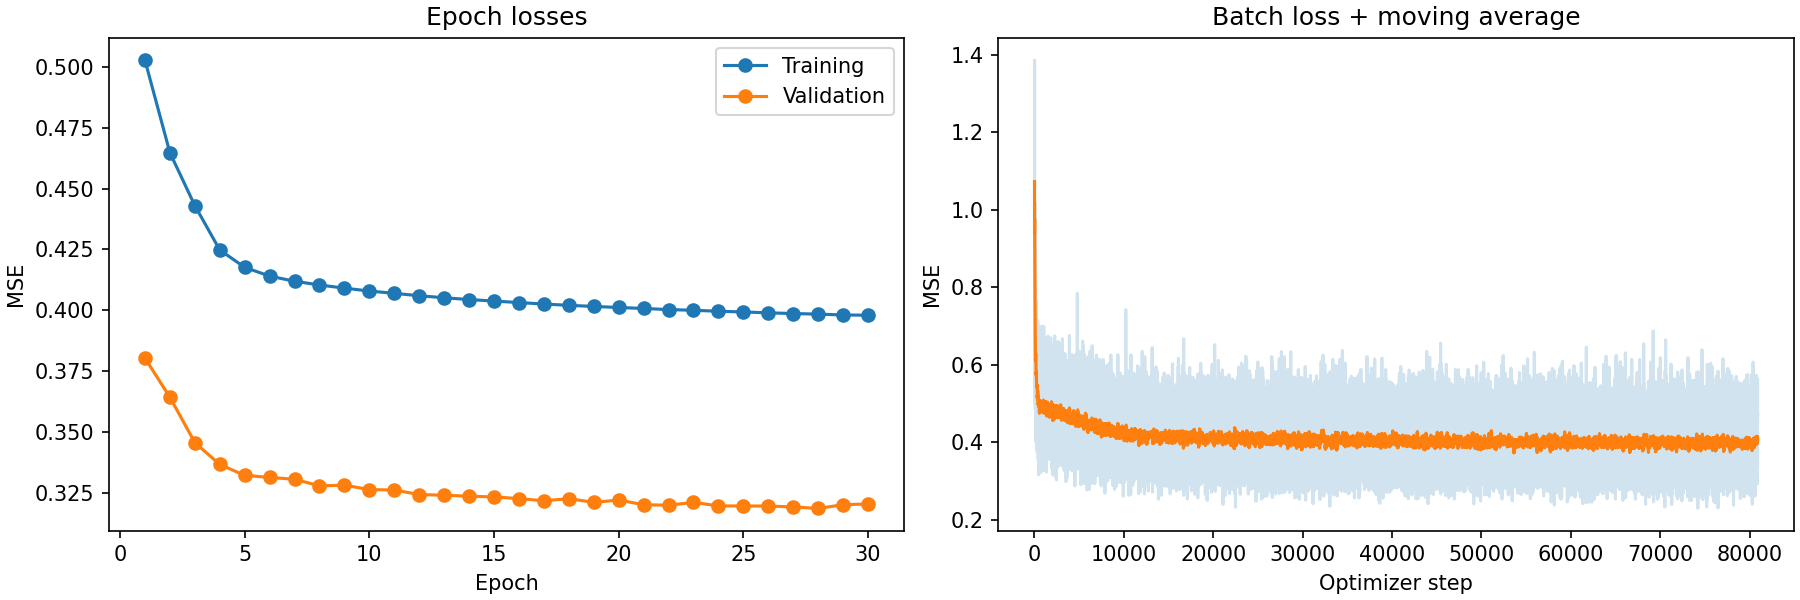

In [6]:
if not train_new and (checkpoint.parent / "curves.png").exists():
    display(Image(filename=str(checkpoint.parent / "curves.png")))
elif history:
    plot_training_curves(history, batch_history);


## Validation

One-step forecasts, identical windows, training-normalized log1p activity.


In [7]:
regular_gvar = GVAR(A, P=P, K=K).fit(trials(data, "train"))
regular_gvar.to(device)
regular_gvar.S = A.to(device)
regular_gvar.eval()

predictions, regular_predictions, targets, last_values = [], [], [], []
with torch.no_grad():
    for past, future in tqdm(val_loader, desc="Validation", unit="batch"):
        x = past.to(device)
        predictions.append(model(x).unsqueeze(1).cpu())
        regular_predictions.append(regular_gvar(x).unsqueeze(1).cpu())
        targets.append(future)
        last_values.append(past[:, -1:])
targets = torch.cat(targets)
validation = {
    f"Adaptive-GVAR (epoch {history[-1]['epoch']})": summarize(torch.cat(predictions), targets),
    "GVAR (ridge)": summarize(torch.cat(regular_predictions), targets),
    "Copy-last": summarize(torch.cat(last_values), targets),
    "Training mean": summarize(torch.zeros_like(targets), targets),
}
validation_table = pd.DataFrame({
    name: {metric: values[0] for metric, values in scores.items()}
    for name, scores in validation.items()
}).T.rename(columns={"mse": "MSE", "rmse": "RMSE", "mae": "MAE", "pearson": "Pearson r", "r2": "R²"})
display(validation_table.round(4))


,MSE,RMSE,MAE,Pearson r,R²
Adaptive-GVAR (epoch 28),0.3186,0.5644,0.2786,0.7706,0.5893
GVAR (ridge),0.4380,0.6618,0.3700,0.6676,0.4381
Copy-last,0.6206,0.7878,0.3043,0.6055,0.2108
Training mean,0.8154,0.9030,0.6252,0.0000,-0.0901
